In [1]:

!pip install -q kagglehub shap seaborn scikit-learn


In [2]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
import shap
import warnings

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')

print("All libraries imported successfully!")


All libraries imported successfully!


In [3]:

# Download Heart Failure Clinical Records dataset

path = kagglehub.dataset_download(
    "andrewmvd/heart-failure-clinical-data"
)

print("Dataset downloaded at:", path)

# Find CSV file
csv_files = [
    file for file in os.listdir(path)
    if file.endswith('.csv')
]

df = pd.read_csv(os.path.join(path, csv_files[0]))

print("Dataset loaded successfully!")


Using Colab cache for faster access to the 'heart-failure-clinical-data' dataset.
Dataset downloaded at: /kaggle/input/heart-failure-clinical-data
Dataset loaded successfully!


In [4]:

df.head()


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


In [5]:

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())


Number of rows: 299
Number of columns: 13

Column Names:
['age', 'anaemia', 'creatinine_phosphokinase', 'diabetes', 'ejection_fraction', 'high_blood_pressure', 'platelets', 'serum_creatinine', 'serum_sodium', 'sex', 'smoking', 'time', 'DEATH_EVENT']

Data Types:
age                         float64
anaemia                       int64
creatinine_phosphokinase      int64
diabetes                      int64
ejection_fraction             int64
high_blood_pressure           int64
platelets                   float64
serum_creatinine            float64
serum_sodium                  int64
sex                           int64
smoking                       int64
time                          int64
DEATH_EVENT                   int64
dtype: object

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 299 entries, 0 to 298
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age          

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
count,299.000000,299.000000,299.000000,299.000000,299.000000,299.000000,299.000000,299.00000,299.000000,299.000000,299.00000,299.000000,299.00000
mean,60.833893,0.431438,581.839465,0.418060,38.083612,0.351171,263358.029264,1.39388,136.625418,0.648829,0.32107,130.260870,0.32107
std,11.894809,0.496107,970.287881,0.494067,11.834841,0.478136,97804.236869,1.03451,4.412477,0.478136,0.46767,77.614208,0.46767
min,40.000000,0.000000,23.000000,0.000000,14.000000,0.000000,25100.000000,0.50000,113.000000,0.000000,0.00000,4.000000,0.00000
25%,51.000000,0.000000,116.500000,0.000000,30.000000,0.000000,212500.000000,0.90000,134.000000,0.000000,0.00000,73.000000,0.00000
50%,60.000000,0.000000,250.000000,0.000000,38.000000,0.000000,262000.000000,1.10000,137.000000,1.000000,0.00000,115.000000,0.00000
75%,70.000000,1.000000,582.000000,1.000000,45.000000,1.000000,303500.000000,1.40000,140.000000,1.000000,1.00000,203.000000,1.00000
max,95.000000,1.000000,7861.000000,1.000000,80.000000,1.000000,850000.000000,9.40000,148.000000,1.000000,1.00000,285.000000,1.00000


In [6]:

print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:")
print(df.isnull().sum().sum())


Missing values in each column:
age                         0
anaemia                     0
creatinine_phosphokinase    0
diabetes                    0
ejection_fraction           0
high_blood_pressure         0
platelets                   0
serum_creatinine            0
serum_sodium                0
sex                         0
smoking                     0
time                        0
DEATH_EVENT                 0
dtype: int64

Total missing values:
0


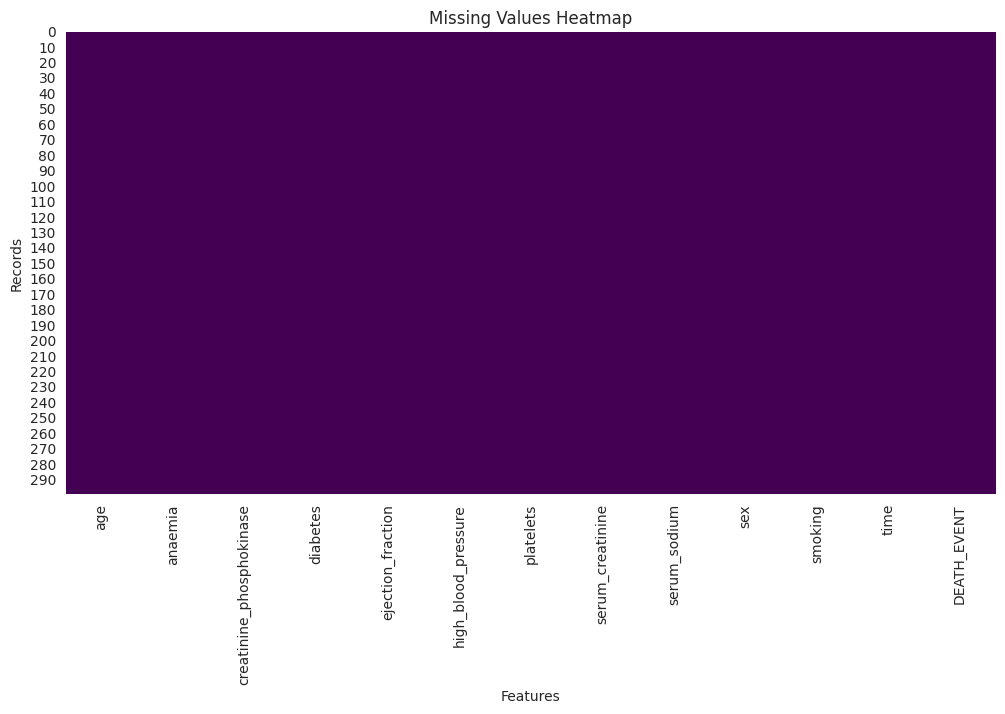

In [7]:

plt.figure(figsize=(12, 6))

sns.heatmap(
    df.isnull(),
    cmap='viridis',
    cbar=False
)

plt.title("Missing Values Heatmap")
plt.xlabel("Features")
plt.ylabel("Records")
plt.show()


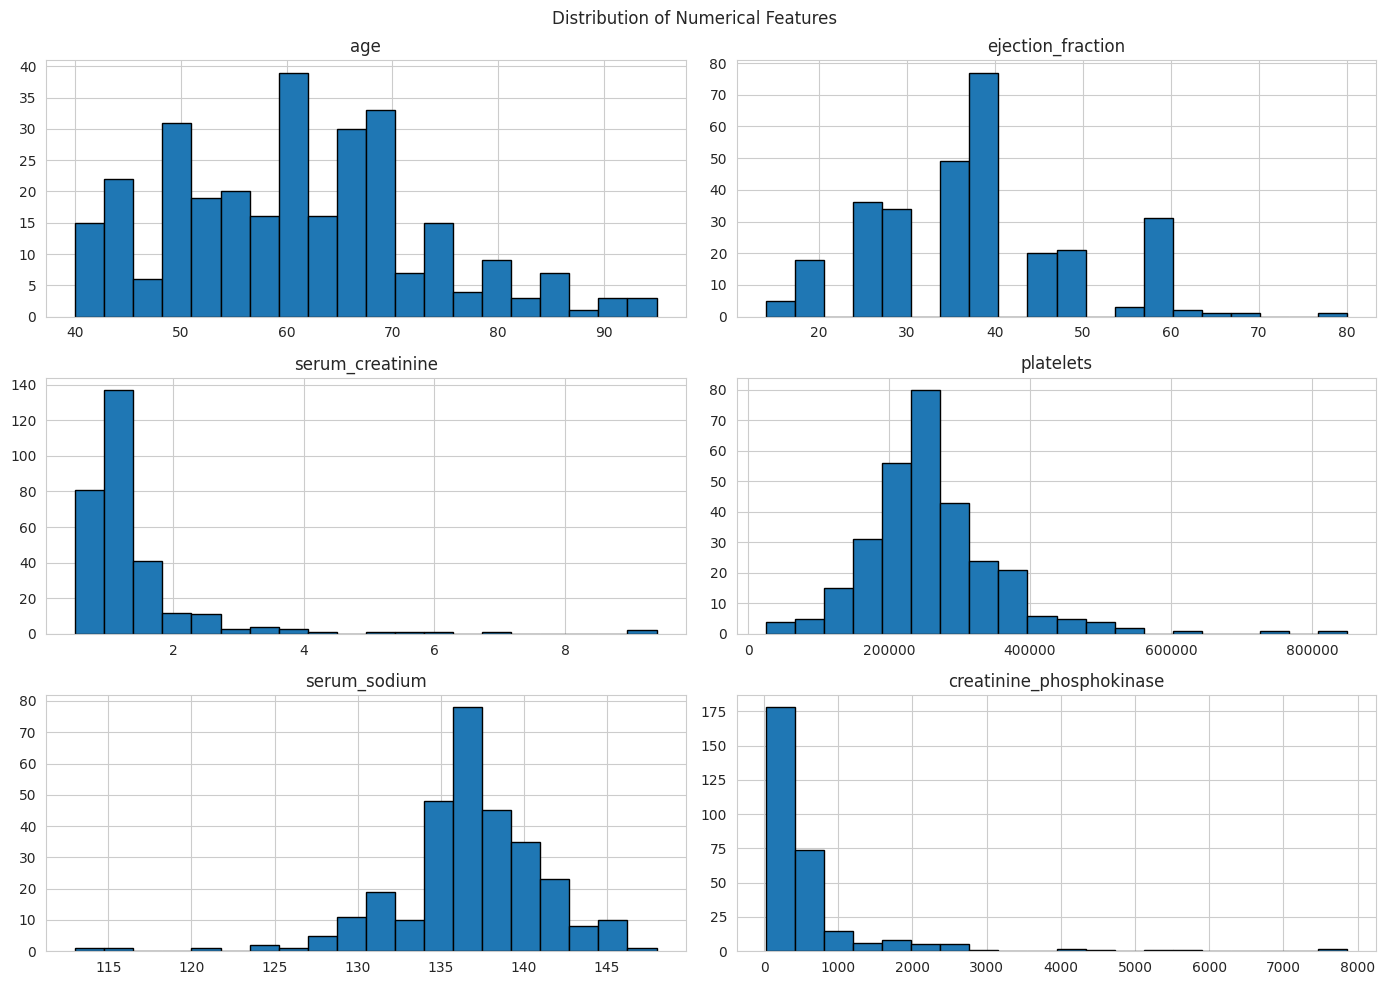

In [8]:

features = [
    'age',
    'ejection_fraction',
    'serum_creatinine',
    'platelets',
    'serum_sodium',
    'creatinine_phosphokinase'
]

df[features].hist(
    figsize=(14, 10),
    bins=20,
    edgecolor='black'
)

plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()


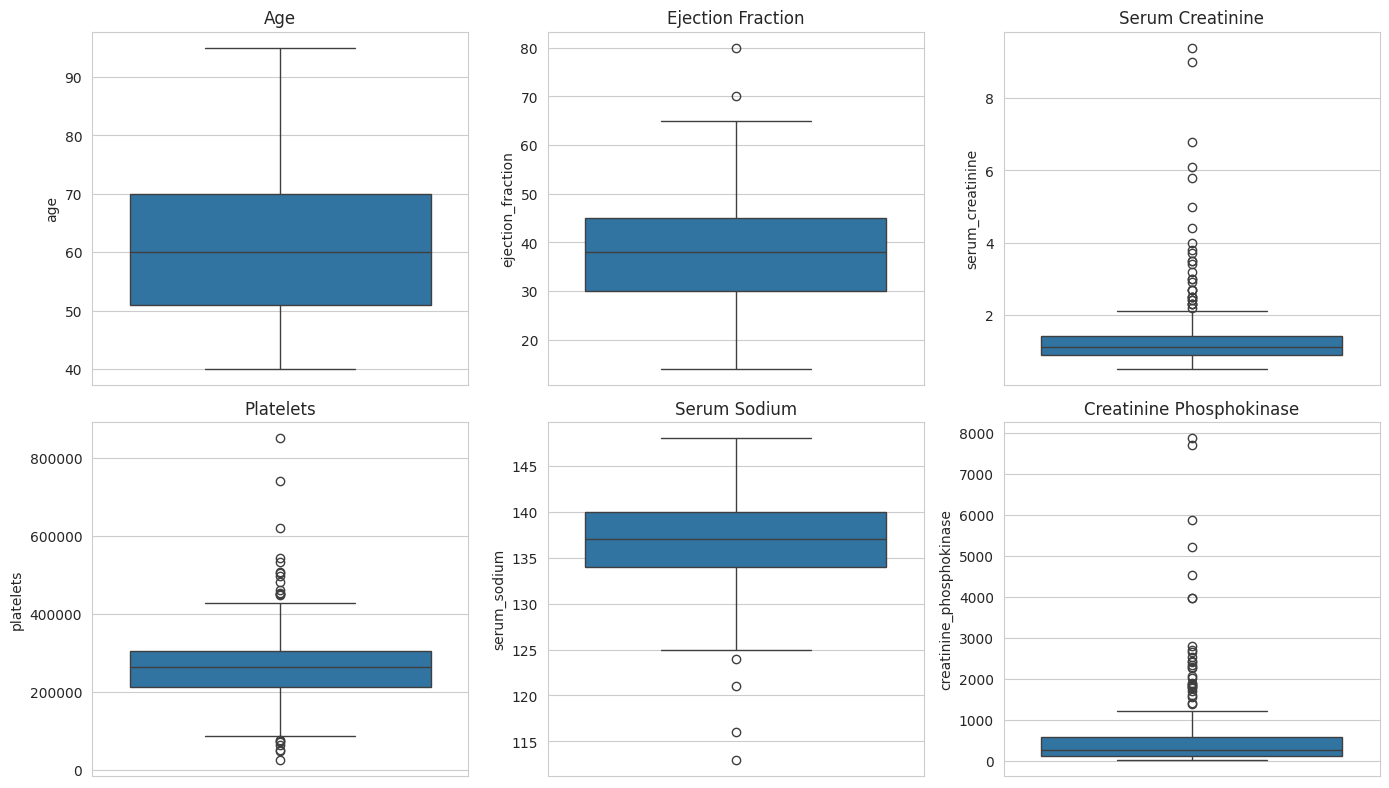

In [9]:

plt.figure(figsize=(14, 8))

for i, feature in enumerate(features, 1):

    plt.subplot(2, 3, i)

    sns.boxplot(y=df[feature])

    plt.title(feature.replace('_', ' ').title())

plt.tight_layout()
plt.show()


In [10]:

# Separate numerical and categorical columns

categorical_cols = [
    'sex',
    'smoking',
    'diabetes',
    'anaemia',
    'high_blood_pressure'
]

target = 'DEATH_EVENT'

numerical_cols = [
    col for col in df.columns
    if col not in categorical_cols + [target]
]

# Display missing values
print("Numerical missing values:")
print(df[numerical_cols].isnull().sum())

print("\nCategorical missing values:")
print(df[categorical_cols].isnull().sum())

print("\nMissing values will be imputed during preprocessing.")


Numerical missing values:
age                         0
creatinine_phosphokinase    0
ejection_fraction           0
platelets                   0
serum_creatinine            0
serum_sodium                0
time                        0
dtype: int64

Categorical missing values:
sex                    0
smoking                0
diabetes               0
anaemia                0
high_blood_pressure    0
dtype: int64

Missing values will be imputed during preprocessing.


In [11]:

# Remove records with invalid clinical values

valid_mask = (
    (df['age'].isna() | (df['age'] >= 0)) &
    (df['ejection_fraction'].isna() |
     df['ejection_fraction'].between(0, 100)) &
    (df['creatinine_phosphokinase'].isna() |
     (df['creatinine_phosphokinase'] >= 0)) &
    (df['platelets'].isna() | (df['platelets'] >= 0)) &
    (df['serum_creatinine'].isna() |
     (df['serum_creatinine'] >= 0)) &
    (df['serum_sodium'].isna() | (df['serum_sodium'] > 0))
)

# Check binary columns
binary_cols = categorical_cols + [target]

for col in binary_cols:
    valid_mask &= df[col].isna() | df[col].isin([0, 1])

df = df.loc[valid_mask].copy()

print("Dataset after consistency checks:", df.shape)


Dataset after consistency checks: (299, 13)


In [12]:

X = df.drop('DEATH_EVENT', axis=1)
y = df['DEATH_EVENT']

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())


Input features shape: (299, 12)
Target shape: (299,)

Target distribution:
DEATH_EVENT
0    203
1     96
Name: count, dtype: int64


In [13]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))


Training records: 239
Testing records: 60


In [14]:

# Fit imputers only on training data

num_imputer = SimpleImputer(strategy='median')
cat_imputer = SimpleImputer(strategy='most_frequent')

X_train = X_train.copy()
X_test = X_test.copy()

X_train[numerical_cols] = num_imputer.fit_transform(
    X_train[numerical_cols]
)

X_test[numerical_cols] = num_imputer.transform(
    X_test[numerical_cols]
)

X_train[categorical_cols] = cat_imputer.fit_transform(
    X_train[categorical_cols]
)

X_test[categorical_cols] = cat_imputer.transform(
    X_test[categorical_cols]
)

print("Missing values imputed successfully!")

print("Training missing values:", X_train.isnull().sum().sum())
print("Testing missing values:", X_test.isnull().sum().sum())


Missing values imputed successfully!
Training missing values: 0
Testing missing values: 0


In [15]:

outlier_features = [
    'age',
    'creatinine_phosphokinase',
    'ejection_fraction',
    'platelets',
    'serum_creatinine',
    'serum_sodium'
]

outlier_mask = pd.Series(False, index=X_train.index)

for feature in outlier_features:

    Q1 = X_train[feature].quantile(0.25)
    Q3 = X_train[feature].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    feature_mask = (
        (X_train[feature] < lower) |
        (X_train[feature] > upper)
    )

    outlier_mask |= feature_mask

print("Potential outlier records:", outlier_mask.sum())

# Remove outliers from training set
X_train = X_train.loc[~outlier_mask].copy()
y_train = y_train.loc[X_train.index].copy()

print("Training shape after outlier removal:", X_train.shape)
print("Testing shape:", X_test.shape)


Potential outlier records: 64
Training shape after outlier removal: (175, 12)
Testing shape: (60, 12)


In [16]:

def create_age_group(data):

    return pd.cut(
        data['age'],
        bins=[-np.inf, 40, 60, np.inf],
        labels=['Below 40', '40-60', 'Above 60'],
        right=False
    )

X_train['age_group'] = create_age_group(X_train)
X_test['age_group'] = create_age_group(X_test)

print(X_train[['age', 'age_group']].head(10))


      age age_group
115  58.0     40-60
23   53.0     40-60
0    75.0  Above 60
194  45.0     40-60
121  66.0  Above 60
106  55.0     40-60
161  45.0     40-60
233  53.0     40-60
265  50.0     40-60
116  60.0  Above 60


In [17]:

# Get normalization limits from training data

ef_min = X_train['ejection_fraction'].min()
ef_max = X_train['ejection_fraction'].max()

cr_min = X_train['serum_creatinine'].min()
cr_max = X_train['serum_creatinine'].max()

def create_risk_score(data):

    ef_range = max(ef_max - ef_min, 1e-10)
    cr_range = max(cr_max - cr_min, 1e-10)

    ef_norm = (
        (data['ejection_fraction'] - ef_min) / ef_range
    )

    cr_norm = (
        (data['serum_creatinine'] - cr_min) / cr_range
    )

    return (1 - ef_norm) * cr_norm

X_train['risk_score'] = create_risk_score(X_train)
X_test['risk_score'] = create_risk_score(X_test)

print(
    X_train[
        ['ejection_fraction', 'serum_creatinine', 'risk_score']
    ].head()
)


     ejection_fraction  serum_creatinine  risk_score
115               40.0               1.0    0.133333
23                60.0               0.8    0.013333
0                 20.0               1.9    0.780000
194               20.0               1.6    0.600000
121               38.0               1.0    0.144000


In [18]:

# Convert categorical features into string values

encode_cols = categorical_cols + ['age_group']

for col in encode_cols:
    X_train[col] = X_train[col].astype(str)
    X_test[col] = X_test[col].astype(str)

# One-hot encoding
X_train = pd.get_dummies(
    X_train,
    columns=encode_cols,
    dtype=int
)

X_test = pd.get_dummies(
    X_test,
    columns=encode_cols,
    dtype=int
)

# Ensure both datasets have identical columns
X_test = X_test.reindex(
    columns=X_train.columns,
    fill_value=0
)

print("Encoded training shape:", X_train.shape)
print("Encoded testing shape:", X_test.shape)

display(X_train.head())


Encoded training shape: (175, 20)
Encoded testing shape: (60, 20)


,age,creatinine_phosphokinase,ejection_fraction,platelets,serum_creatinine,serum_sodium,time,risk_score,sex_0,sex_1,smoking_0,smoking_1,diabetes_0,diabetes_1,anaemia_0,anaemia_1,high_blood_pressure_0,high_blood_pressure_1,age_group_40-60,age_group_Above 60
115,58.0,400.0,40.0,164000.0,1.0,139.0,91.0,0.133333,1,0,1,0,1,0,0,1,1,0,1,0
23,53.0,63.0,60.0,368000.0,0.8,135.0,22.0,0.013333,0,1,1,0,0,1,1,0,1,0,1,0
0,75.0,582.0,20.0,265000.0,1.9,130.0,4.0,0.780000,0,1,1,0,1,0,1,0,0,1,0,1
194,45.0,582.0,20.0,126000.0,1.6,135.0,180.0,0.600000,0,1,1,0,1,0,1,0,0,1,1,0
121,66.0,68.0,38.0,162000.0,1.0,136.0,95.0,0.144000,1,0,1,0,0,1,0,1,0,1,0,1


In [20]:

scale_cols = numerical_cols + ['risk_score']

scaler = MinMaxScaler()

X_train = X_train.copy()
X_test = X_test.copy()

X_train[scale_cols] = scaler.fit_transform(
    X_train[scale_cols]
)

X_test[scale_cols] = scaler.transform(
    X_test[scale_cols]
)

print("Normalization completed!")

display(X_train.head())


Normalization completed!


,age,creatinine_phosphokinase,ejection_fraction,platelets,serum_creatinine,serum_sodium,time,risk_score,sex_0,sex_1,smoking_0,smoking_1,diabetes_0,diabetes_1,anaemia_0,anaemia_1,high_blood_pressure_0,high_blood_pressure_1,age_group_40-60,age_group_Above 60
115,0.333333,0.315700,0.50,0.137705,0.266667,0.647059,0.327068,0.166667,1,0,1,0,1,0,0,1,1,0,1,0
23,0.240741,0.028157,0.90,0.806557,0.133333,0.411765,0.067669,0.016667,0,1,1,0,0,1,1,0,1,0,1,0
0,0.648148,0.470990,0.10,0.468852,0.866667,0.117647,0.000000,0.975000,0,1,1,0,1,0,1,0,0,1,0,1
194,0.092593,0.470990,0.10,0.013115,0.666667,0.411765,0.661654,0.750000,0,1,1,0,1,0,1,0,0,1,1,0
121,0.481481,0.032423,0.46,0.131148,0.266667,0.470588,0.342105,0.180000,1,0,1,0,0,1,0,1,0,1,0,1


In [21]:

model = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    random_state=42,
    class_weight='balanced'
)

# Train the model
model.fit(X_train, y_train)

print("Random Forest model trained successfully!")


Random Forest model trained successfully!


In [22]:

# Predict class labels
y_pred = model.predict(X_test)

# Predict probabilities for death event
y_prob = model.predict_proba(X_test)[:, 1]

print("Actual values:")
print(y_test.head(10).values)

print("\nPredicted values:")
print(y_pred[:10])


Actual values:
[0 0 0 0 0 0 0 1 0 0]

Predicted values:
[0 0 0 0 0 0 0 0 0 1]


In [23]:

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, zero_division=0
)

recall = recall_score(
    y_test, y_pred, zero_division=0
)

f1 = f1_score(
    y_test, y_pred, zero_division=0
)

roc_auc = roc_auc_score(y_test, y_prob)

print("MODEL PERFORMANCE")
print("-------------------------")
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Score :", round(f1, 4))
print("ROC-AUC  :", round(roc_auc, 4))


MODEL PERFORMANCE
-------------------------
Accuracy : 0.85
Precision: 0.8571
Recall   : 0.6316
F1 Score : 0.7273
ROC-AUC  : 0.8832


In [24]:

print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            'No Death Event',
            'Death Event'
        ],
        zero_division=0
    )
)


                precision    recall  f1-score   support

No Death Event       0.85      0.95      0.90        41
   Death Event       0.86      0.63      0.73        19

      accuracy                           0.85        60
     macro avg       0.85      0.79      0.81        60
  weighted avg       0.85      0.85      0.84        60



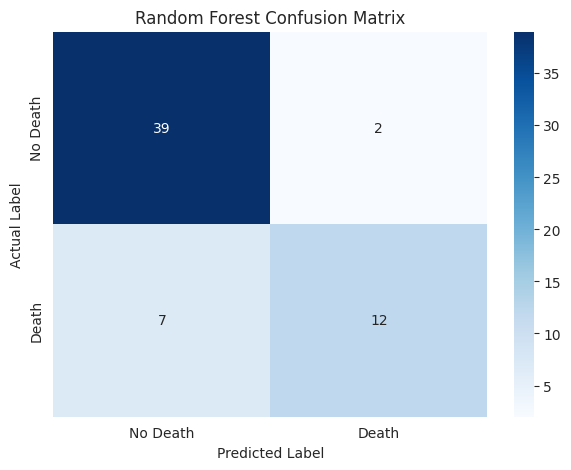

In [25]:

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Death', 'Death'],
    yticklabels=['No Death', 'Death']
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()


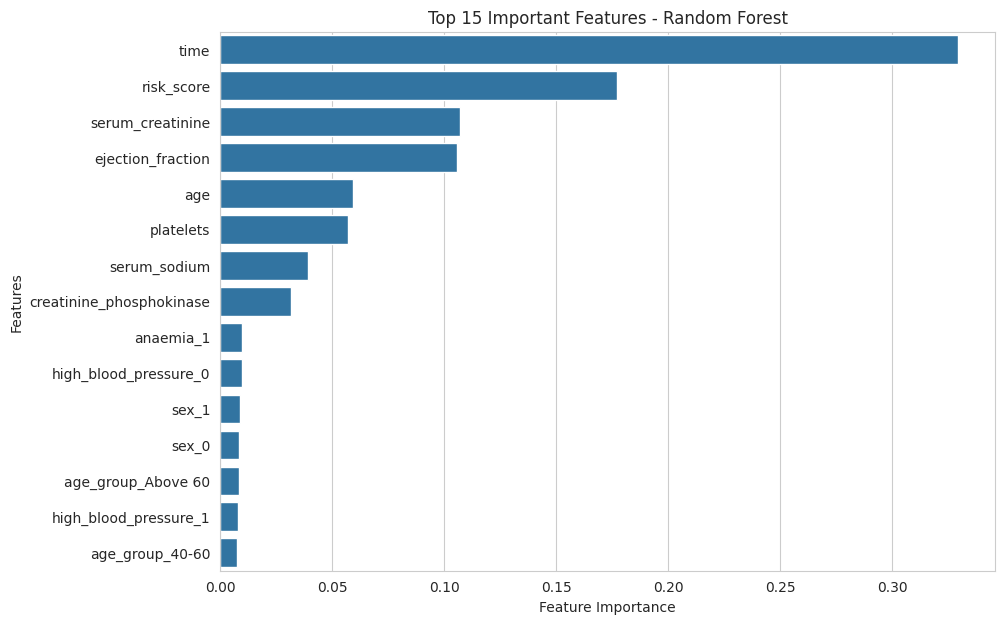

In [26]:

importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': model.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=importance.head(15),
    x='Importance',
    y='Feature'
)

plt.title("Top 15 Important Features - Random Forest")
plt.xlabel("Feature Importance")
plt.ylabel("Features")

plt.show()


In [27]:

# Create TreeExplainer for Random Forest

explainer = shap.TreeExplainer(model)

# Calculate SHAP values
shap_values = explainer.shap_values(X_test)

print("SHAP values calculated successfully!")


SHAP values calculated successfully!


In [28]:

# Extract SHAP values for class 1 (Death Event)

if isinstance(shap_values, list):

    death_shap = shap_values[1]

elif isinstance(shap_values, np.ndarray) and shap_values.ndim == 3:

    death_shap = shap_values[:, :, 1]

else:

    death_shap = shap_values

print("SHAP values shape:", death_shap.shape)
print("Test dataset shape:", X_test.shape)


SHAP values shape: (60, 20)
Test dataset shape: (60, 20)


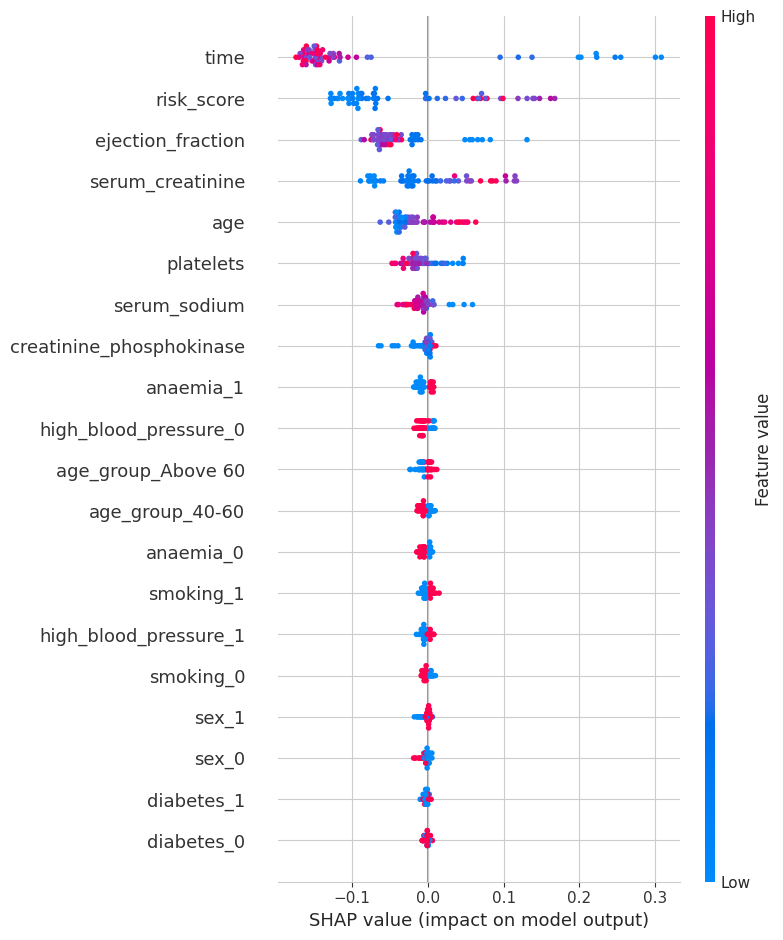

In [29]:

shap.summary_plot(
    death_shap,
    X_test,
    show=True
)


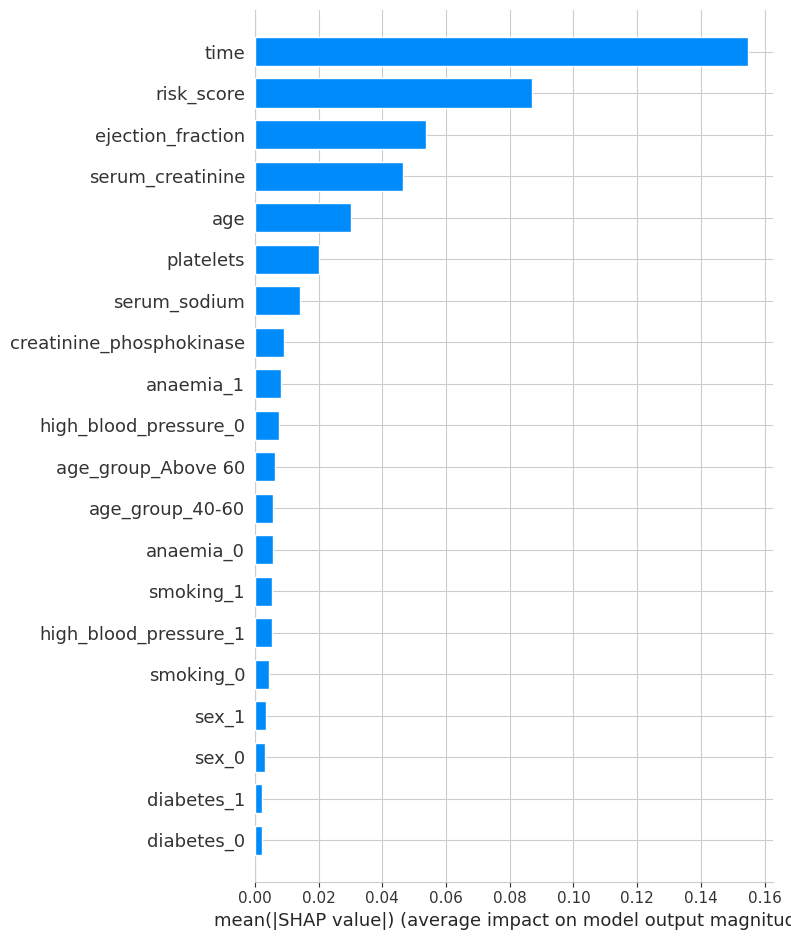

In [30]:

shap.summary_plot(
    death_shap,
    X_test,
    plot_type='bar',
    show=True
)


In [31]:

# Select one patient
patient_index = 0

patient = X_test.iloc[[patient_index]]

# Actual outcome
actual = y_test.iloc[patient_index]

# Predicted outcome
predicted = model.predict(patient)[0]

# Death-event probability
probability = model.predict_proba(patient)[0][1]

print("INDIVIDUAL PATIENT PREDICTION")
print("-----------------------------")

print("Actual outcome:", actual)
print("Predicted outcome:", predicted)

print(
    "Death event probability:",
    round(probability * 100, 2), "%"
)


INDIVIDUAL PATIENT PREDICTION
-----------------------------
Actual outcome: 0
Predicted outcome: 0
Death event probability: 25.68 %


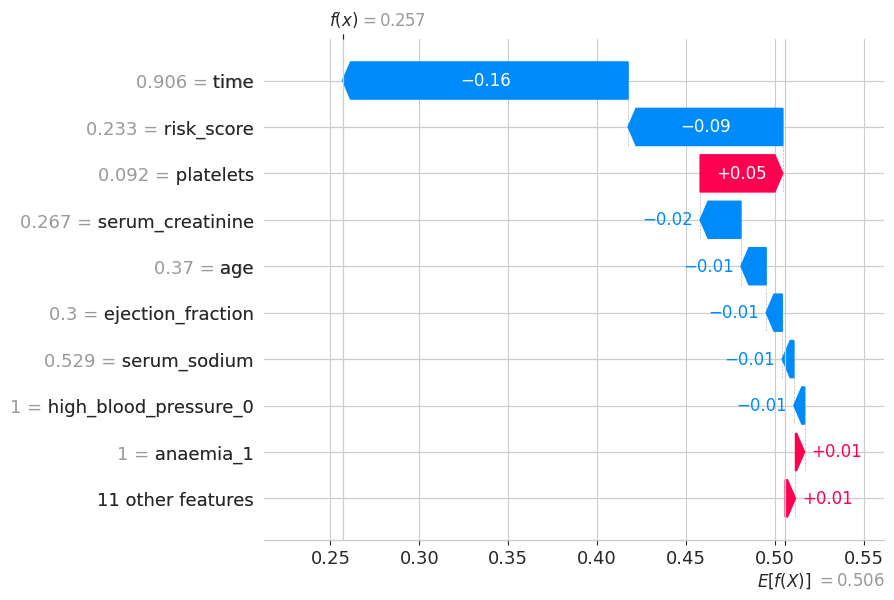

In [32]:

# Create SHAP explanation object

shap_explanation = explainer(X_test)

# Explain the first patient's death-event prediction

if shap_explanation.values.ndim == 3:

    patient_shap = shap_explanation[
        patient_index, :, 1
    ]

else:

    patient_shap = shap_explanation[
        patient_index, :
    ]

shap.plots.waterfall(patient_shap)


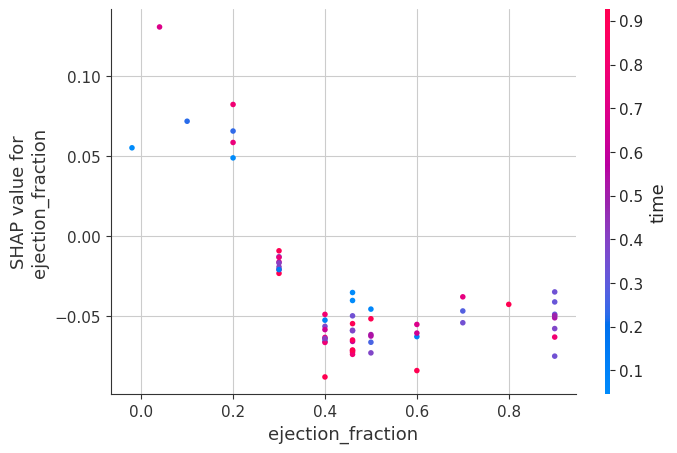

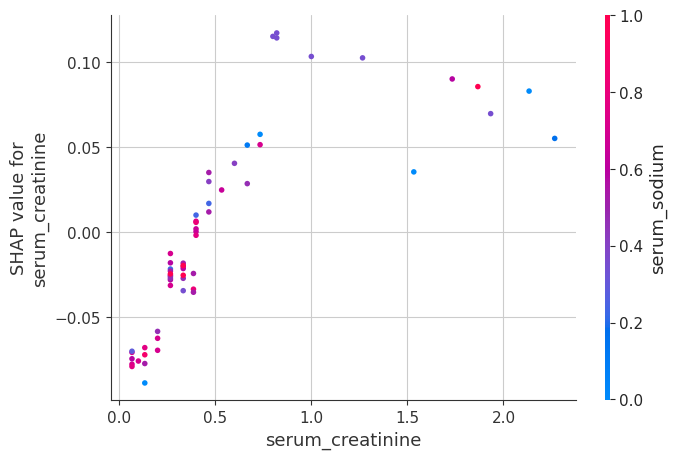

In [33]:

shap.dependence_plot(
    'ejection_fraction',
    death_shap,
    X_test
)

shap.dependence_plot(
    'serum_creatinine',
    death_shap,
    X_test
)


In [34]:

results = pd.DataFrame({
    'Metric': [
        'Accuracy',
        'Precision',
        'Recall',
        'F1 Score',
        'ROC-AUC'
    ],

    'Score': [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ]
})

display(results)


,Metric,Score
0,Accuracy,0.850000
1,Precision,0.857143
2,Recall,0.631579
3,F1 Score,0.727273
4,ROC-AUC,0.883184


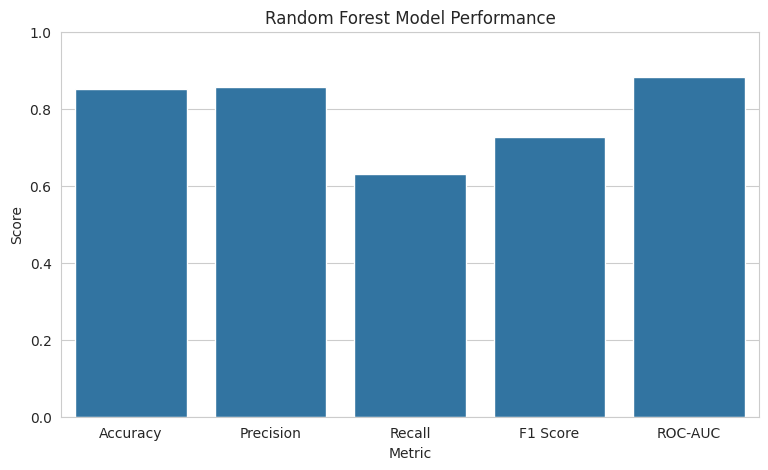

In [35]:

plt.figure(figsize=(9, 5))

sns.barplot(
    data=results,
    x='Metric',
    y='Score'
)

plt.title("Random Forest Model Performance")
plt.ylabel("Score")
plt.ylim(0, 1)

plt.show()


In [36]:

# Save cleaned dataset
df.to_csv(
    'cleaned_heart_failure_dataset.csv',
    index=False
)

# Save model
import joblib

joblib.dump(
    model,
    'heart_failure_random_forest.pkl'
)

# Save performance results
results.to_csv(
    'model_performance.csv',
    index=False
)

print("All files saved successfully!")


All files saved successfully!


In [37]:

print("=" * 50)
print("LAB ASSIGNMENT 11 - FINAL SUMMARY")
print("=" * 50)

print("\nDataset Information")
print("Original dataset shape:", (299, 13))
print("Processed dataset shape:", df.shape)
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nModel: Random Forest Classifier")

print("\nPerformance Metrics")
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Score :", round(f1, 4))
print("ROC-AUC  :", round(roc_auc, 4))

print("\nExplainability:")
print("SHAP Summary Plot: Generated")
print("SHAP Bar Plot: Generated")
print("SHAP Waterfall Plot: Generated")
print("SHAP Dependence Plots: Generated")

print("\nLAB ASSIGNMENT 11 COMPLETED!")


LAB ASSIGNMENT 11 - FINAL SUMMARY

Dataset Information
Original dataset shape: (299, 13)
Processed dataset shape: (299, 13)
Training records: 175
Testing records: 60

Model: Random Forest Classifier

Performance Metrics
Accuracy : 0.85
Precision: 0.8571
Recall   : 0.6316
F1 Score : 0.7273
ROC-AUC  : 0.8832

Explainability:
SHAP Summary Plot: Generated
SHAP Bar Plot: Generated
SHAP Waterfall Plot: Generated
SHAP Dependence Plots: Generated

LAB ASSIGNMENT 11 COMPLETED!
